# AIR-CIS: correspondence importance sampling against MTPFN, A-only and the exact oracle

## Description

*Written before the first run (2026-11-04). Spec and pre-registration: `research_log/entries/2026-11-04_air-cis.md`
(the spec verbatim, then a pre-run addendum with deviations D1–D7). Issue #22.*

**Question.** Is a scarce target task A predicted better by *explicit inference* of how it relates to a dense
source B, than by an *amortised* in-context learner that sees both tasks (MTPFN)? Where does each lie between the
A-only lower bound and the exact Bayes oracle, and which part of the remaining gap is the proposal's and which the
decoder's?

**The task (d = 1).** B: 128 noisy points of a random function g. A: 1–10 noisy points of
f_A(x) = h(g(T(x))), with an unknown monotone transform T of the input and an unknown output map h (identity or
affine). The learner must predict A at 32 held-out queries.

**The prior, without boundary leak.**
- g: a random tanh network with a sampled architecture (depth 1–3, width 16/32/64), mapped to [0, 1] by one
  global ECDF.
- T(x) = c + w · Φ_θ(x): a smooth monotone flow Φ_θ of complexity J ∈ {0, 2, 4, 8, 16} (p = 0.2, 0.3, 0.2, 0.15,
  0.15) with a random amplitude s_T, followed by a random window (w ∈ [0.5, 1], c ∈ [0, 1 − w]).
  *Why the window:* Φ_θ alone fixes both ends of the box, so with h = id B would reveal A's values at x = 0 and
  x = 1 exactly, and at J = 0 everywhere. A Bayes learner exploits that, and it made the predictive in notebooks
  15–16 artificially sharp at the edges. With the window, A's box maps into a random sub-interval of B's, and no
  value of A is known from B alone.
- h = id with probability 0.5, else a + b·v with b ∈ [0.3, 1], a ∈ [0, 1 − b]. Noise σ_A, σ_B ∈ [0.005, 0.03].
  Always related (no unrelated B in this stage).

**The idea: CIS (correspondence importance sampling).** The posterior over T is hard because it is
*discrete at heart*: g is not monotone, so an A point with value y_a could sit on any of the branches of g where g
≈ y_a. A smooth proposal (AIR's flow) blurs these branches together. CIS proposes them explicitly:
1. *B surrogate.* A GP on B gives μ_B(u), σ_B(u) (proposal only).
2. *Claims.* Every A point claims a set of candidate locations u in B (the 16 best-matching B points by
   N(y_a; μ_B(u), …) times a prior table π(u | x_a), plus the 4 most likely under the prior).
3. *Coherent assignments by FFBS.* Along A sorted by x, a hidden-Markov chain over the candidates with a soft
   monotone, smooth transition kernel (from the prior's stretch statistics); forward filtering, backward sampling
   draws whole assignments c, each with its exact probability q(c).
4. *A transform per assignment.* For each sampled c, and each J (and each h type), Gauss–Newton fits the transform
   to "T(x_a) lands on c_a" and to A's values through μ_B; a Laplace Gaussian around the fit is the proposal for
   θ, and the Laplace evidence gives q(J | c).
5. *Exact weights.* θ is drawn from the Laplace mixture (plus 10 % prior), and the importance weight uses the
   transported decoder D's likelihood p̂(A | B, θ), with an auxiliary term r(c | θ) that keeps the target exactly the
   posterior over (J, θ). The prediction is the weighted mixture of D's predictives.
6. *Rounds (U).* Two cheap rounds with GP-surrogate weights reshape the location prior (a KDE of where the
   weighted transforms send each A point) and add local candidates; only the last round, with decoder weights,
   enters the estimate. The proposal can be wrong without biasing the result: errors cost effective sample size.

The decoder D is AIR's transported PFN: it predicts A from A's points and B moved into A's frame by T⁻¹, with a new
feature log (T⁻¹)′(x_b) (how much the transform stretches B there), retrained on this prior.

**Setup.** Identical 256 evaluation tasks per n_A ∈ {1, 2, 3, 5, 8, 10} (CPU-drawn, fixed seed) for every method:
- **A-only**: a PFN with MTPFN's architecture trained on A alone (the clean lower bound); D's null head also shown.
- **MTPFN**: #20's architecture (1.8 M parameters) trained on this prior, A and B as two tasks.
- **CIS-U**: R = 1 and R = 3 rounds, K ∈ {32, 128} final samples.
- **IS-ref**: prior importance sampling with K = 8192 and the same decoder: what CIS would reach with a perfect
  proposal.
- **Teacher**: D at the true transform: the decoder's best case.
- **Oracle**: the exact posterior predictive given the true g and σ_A (h integrated analytically; T's latents by
  tempered SMC per J, J mixed by the SMC evidence). An upper bound no method can beat in expectation.
All trained components: seed 0 in this stage.

**What to look for, and why.**
1. *The ladder* (the main figure): NLL against n_A for A-only, MTPFN, CIS, IS-ref, teacher, oracle, and the share of
   the A-only → oracle gap each closes. Answers "where does each method lie".
2. *Paired CIS − MTPFN* per n_A with bootstrap CIs, overall and by stratum (J, number of extrema of g, true h).
   CIS should win where the posterior is multimodal (many extrema, high J, small n_A) and may lose nothing
   elsewhere.
3. *Decomposition* of CIS's gap: proposal (CIS − IS-ref) vs decoder (IS-ref − oracle). In #21 (J = 2, AIR prior)
   proposals were within 0.02 nats of IS-ref and the decoder cost 0.11–0.16 nats; if that holds here, the next
   step is the decoder, not the proposal.
4. *Proposal diagnostics*: ESS/K, branch hit rate and q-mass on the true branch combination by extrema stratum,
   R = 1 vs 3, K = 32 vs 128; the J posterior against the oracle's p(J | A, B) (calibration).
5. *Calibration of the predictive* (PIT histograms, 50/90 % interval coverage) of MTPFN, CIS and the oracle: is a
   sharp predictive earned?
6. *Leak audit*: the oracle's gain over A-only by the distance of x* to the boundary (h = id). A flat profile
   means B does not reveal A's edge values.
7. *Negative transfer*: the share of tasks where each method is worse than A-only. *Runtime* per task.

**GO / NO-GO** (this notebook's comparison; the spec's C1, C3–C6 are evaluated as written, C2/C7/C8 are out of
stage 1). **GO**: CIS-U (R = 3, K = 128) beats MTPFN by ≥ 0.05 nats with a paired 95 % CI excluding 0 at ≥ 2 of
n_A ∈ {2, 3, 5}, and is not significantly worse at any n_A. **NO-GO**: CIS is significantly better at none of
n_A ∈ {2, 3, 5}. Otherwise **INCONCLUSIVE**.

**Limits.** d = 1 only; always related (no unrelated-source stratum, so negative transfer is only tested within
the related prior); h is identity or affine (no non-monotone h); one seed per trained model; the oracle knows g
exactly (B is dense but noisy for every learner), so its gap is a bound, not a target; the decoder and MTPFN are
trained on the same prior, so prior mismatch does not enter the comparison.


# Results

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from meta_pfn.analysis import bootstrap_ci

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir() and (p / "src").is_dir()), Path.cwd())
SWEEP = "pilot_20261104-202203"
TB = ROOT / "results/air_cis" / SWEEP / "tables"
nll, q, diag, tasks = (pd.read_parquet(TB / f"{k}.parquet") for k in ("nll", "query", "diag", "tasks"))
tasks["ext"] = np.where(tasks.n_ext >= 3, "≥3", tasks.n_ext.astype(str))
tasks["h"] = np.where(tasks.h_id, "h = id", "h affine")
nll = nll.merge(tasks[["task", "J", "ext", "h", "sig_a"]], on="task")
P = nll.pivot_table(index=["n_a", "task"], columns="method", values="nll")
NS = sorted(nll.n_a.unique())
print("eval sweep:", SWEEP, "| tasks per (method, n_A):", nll.groupby(["method", "n_a"]).size().unique(),
      "| methods:", sorted(nll.method.unique()))
print("strata (tasks): J", tasks.J.value_counts().sort_index().to_dict(), "| extrema", tasks.ext.value_counts().to_dict(),
      "| h = id", int(tasks.h_id.sum()))

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2,
                     "lines.markersize": 6, "text.color": INK, "axes.labelcolor": MUTED, "font.size": 10,
                     "legend.frameon": False})  # fmt: skip
CIS = "cis_r3_k128"
LADDER = [("aonly", "A-only (clean PFN)", MUTED, "--"), ("null", "decoder null head", MUTED, ":"),
          ("mtpfn", "MTPFN", C[0], "-"), (CIS, "CIS-U (R=3, K=128)", C[1], "-"), ("isref", "IS-ref (K=8192)", C[3], "-."),
          ("teacher", "teacher (true θ)", C[2], "-."), ("cis_exact_r3_k128", "CIS, exact likelihood", C[4], ":"),
          ("oracle", "oracle", INK, "--")]  # fmt: skip
LADDER = [r for r in LADDER if r[0] in P.columns]

eval sweep: pilot_20261104-202203 | tasks per (method, n_A): [256] | methods: ['aonly', 'cis_exact_r3_k128', 'cis_r1_k128', 'cis_r1_k32', 'cis_r3_k128', 'cis_r3_k32', 'isref', 'mtpfn', 'null', 'oracle', 'teacher']
strata (tasks): J {0: 60, 2: 72, 4: 42, 8: 38, 16: 44} | extrema {'1': 99, '0': 90, '2': 47, '≥3': 20} | h = id 112


## 1. Oracle quality

The oracle's MC error per task: the mean over queries of |half 1 − half 2| of its log predictive density (two
independent SMC runs of 1024 particles per J). This is about √2 × the standard error of one half; the reported
oracle averages both halves.

In [ ]:
o = nll[nll.method == "oracle"]
display(o.groupby("n_a").mc.agg(["mean", "median", lambda v: v.quantile(0.95), "max"]).set_axis(
    ["mean", "median", "p95", "max"], axis=1).round(4))

,mean,median,p95,max
n_a,,,,
1,0.0194,0.0164,0.0409,0.1216
2,0.0196,0.0145,0.0502,0.1870
3,0.0168,0.0119,0.0453,0.1586
5,0.0162,0.0106,0.0485,0.1429
8,0.0145,0.0091,0.0400,0.2357
10,0.0137,0.0082,0.0395,0.1578


## 2. The ladder: A-only ≥ … ≥ oracle

The NLL per held-out query of A (mean over the 256 tasks; ± is the SE over tasks). Share = (A-only − method) /
(A-only − oracle).

,A-only (clean PFN),decoder null head,MTPFN,"CIS-U (R=3, K=128)",IS-ref (K=8192),teacher (true θ),"CIS, exact likelihood",oracle
n_A,,,,,,,,
1,-1.389 ± 0.050,-1.386 ± 0.051,-1.892 ± 0.033,-1.921 ± 0.034,-1.930 ± 0.033,-2.242 ± 0.033,-1.972 ± 0.040,-2.018 ± 0.036
2,-1.723 ± 0.040,-1.718 ± 0.041,-2.053 ± 0.030,-2.082 ± 0.031,-2.100 ± 0.030,-2.369 ± 0.027,-2.156 ± 0.038,-2.196 ± 0.034
3,-1.922 ± 0.036,-1.920 ± 0.036,-2.155 ± 0.029,-2.195 ± 0.029,-2.210 ± 0.028,-2.428 ± 0.026,-2.257 ± 0.037,-2.304 ± 0.033
5,-2.130 ± 0.032,-2.121 ± 0.032,-2.265 ± 0.028,-2.310 ± 0.028,-2.318 ± 0.027,-2.483 ± 0.027,-2.360 ± 0.033,-2.411 ± 0.031
8,-2.280 ± 0.031,-2.264 ± 0.032,-2.378 ± 0.028,-2.406 ± 0.027,-2.419 ± 0.027,-2.541 ± 0.027,-2.458 ± 0.032,-2.503 ± 0.031
10,-2.338 ± 0.031,-2.328 ± 0.031,-2.416 ± 0.029,-2.445 ± 0.029,-2.457 ± 0.028,-2.555 ± 0.028,-2.458 ± 0.051,-2.538 ± 0.031


share of the A-only → oracle gap closed


,decoder null head,MTPFN,"CIS-U (R=3, K=128)",IS-ref (K=8192),teacher (true θ),"CIS, exact likelihood"
n_a,,,,,,
1,0 %,80 %,85 %,86 %,136 %,93 %
2,-1 %,70 %,76 %,80 %,137 %,92 %
3,0 %,61 %,71 %,75 %,132 %,88 %
5,-3 %,48 %,64 %,67 %,126 %,82 %
8,-7 %,44 %,57 %,63 %,117 %,80 %
10,-5 %,39 %,54 %,60 %,108 %,60 %


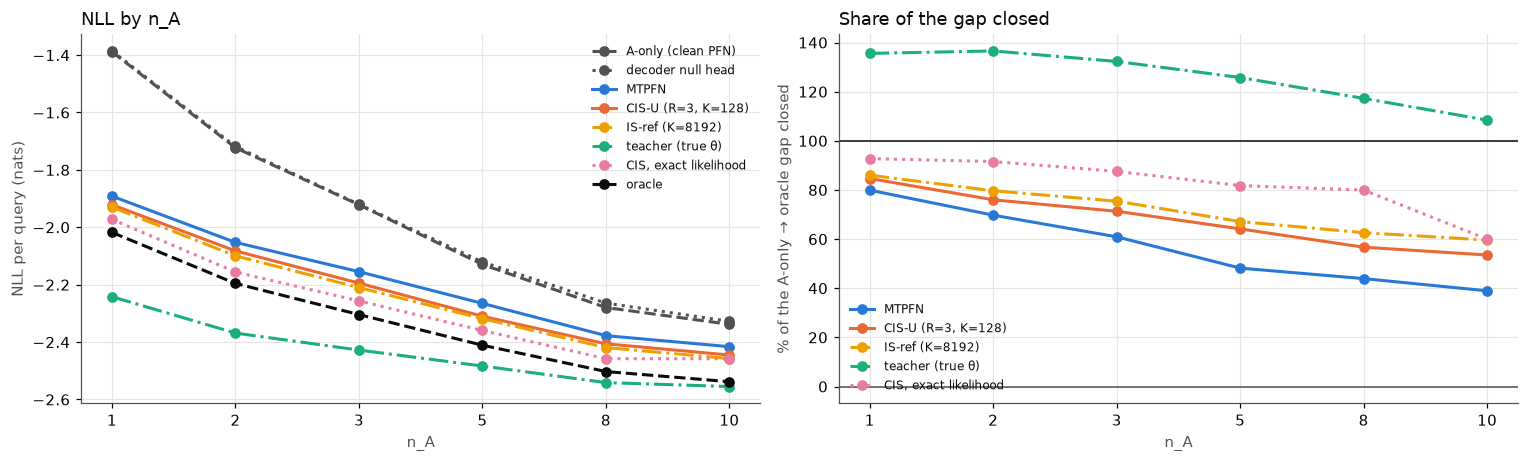

In [ ]:
m, se = P.groupby("n_a").mean(), P.groupby("n_a").sem()
tab = pd.DataFrame({lab: [f"{m.loc[n, k]:.3f} ± {se.loc[n, k]:.3f}" for n in NS] for k, lab, *_ in LADDER}, index=NS)
tab.index.name = "n_A"
display(tab)
share = pd.DataFrame({lab: (m.aonly - m[k]) / (m.aonly - m.oracle) for k, lab, *_ in LADDER if k not in ("aonly", "oracle")})
print("share of the A-only → oracle gap closed")
display((100 * share).round(0).astype(int).astype(str) + " %")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
x = np.arange(len(NS))
for k, lab, col, ls in LADDER:
    axs[0].plot(x, m[k], color=col, ls=ls, marker="o", label=lab)
axs[0].set_xticks(x, NS)
axs[0].set(xlabel="n_A", ylabel="NLL per query (nats)")
axs[0].set_title("NLL by n_A", loc="left")
axs[0].legend(fontsize=8)
for i, (k, lab, col, ls) in enumerate([r for r in LADDER if r[0] not in ("aonly", "oracle", "null")]):
    axs[1].plot(x, 100 * share[lab], color=col, ls=ls, marker="o", label=lab)
axs[1].axhline(100, color=INK, lw=1)
axs[1].axhline(0, color=MUTED, lw=1)
axs[1].set_xticks(x, NS)
axs[1].set(xlabel="n_A", ylabel="% of the A-only → oracle gap closed")
axs[1].set_title("Share of the gap closed", loc="left")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. The pre-registered comparison: CIS-U (R = 3, K = 128) against MTPFN

Paired over tasks: d = CIS − MTPFN per task (negative means CIS is better), with a 95 % bootstrap CI (10 000
resamples). **GO**: d ≤ −0.05 with the CI below 0 at ≥ 2 of n_A ∈ {2, 3, 5}, and CIS not significantly worse at
any n_A. **NO-GO**: CIS significantly better at none of n_A ∈ {2, 3, 5}. Otherwise **INCONCLUSIVE**.

In [ ]:
rows = []
for n in NS:
    d = (P.loc[n][CIS] - P.loc[n]["mtpfn"]).to_numpy()
    lo, hi = bootstrap_ci(d, n_boot=10_000)
    rows.append({"n_A": n, "CIS − MTPFN": d.mean(), "CI lo": lo, "CI hi": hi, "better": hi < 0, "worse": lo > 0,
                 "meets −0.05": (d.mean() <= -0.05) and hi < 0, "share of tasks CIS better": (d < 0).mean()})
V = pd.DataFrame(rows).set_index("n_A")
display(V.round(4))
key = V.loc[[n for n in (2, 3, 5) if n in V.index]]
n_go, any_worse, n_better = int(key["meets −0.05"].sum()), bool(V.worse.any()), int(key.better.sum())
verdict = "GO" if (n_go >= 2 and not any_worse) else ("NO-GO" if n_better == 0 else "INCONCLUSIVE")
print(f"cells meeting the GO margin (n_A in 2, 3, 5): {n_go}; significantly worse anywhere: {any_worse}; "
      f"significantly better (2, 3, 5): {n_better}  ->  proposed verdict: {verdict}")

,CIS − MTPFN,CI lo,CI hi,better,worse,meets −0.05,share of tasks CIS better
n_A,,,,,,,
1,-0.0298,-0.0494,-0.0110,True,False,False,0.5742
2,-0.0295,-0.0491,-0.0096,True,False,False,0.6055
3,-0.0398,-0.0592,-0.0198,True,False,False,0.6055
5,-0.0449,-0.0615,-0.0282,True,False,False,0.6562
8,-0.0285,-0.0451,-0.0127,True,False,False,0.5703
10,-0.0291,-0.0443,-0.0144,True,False,False,0.5938


cells meeting the GO margin (n_A in 2, 3, 5): 0; significantly worse anywhere: False; significantly better (2, 3, 5): 3  ->  proposed verdict: INCONCLUSIVE


## 4. Where the error comes from

- proposal error = CIS − IS-ref (the decoder held fixed);
- decoder error = IS-ref − oracle (and teacher − oracle: the decoder with the true θ);
- MTPFN's amortisation error = MTPFN − oracle;
- proposal quality without the decoder = CIS (exact likelihood) − oracle.

In [ ]:
dec = pd.DataFrame({"proposal: CIS − IS-ref": m[CIS] - m.isref, "decoder: IS-ref − oracle": m.isref - m.oracle,
                    "decoder: teacher − oracle": m.teacher - m.oracle, "MTPFN − oracle": m.mtpfn - m.oracle})
if "cis_exact_r3_k128" in m:
    dec["CIS exact − oracle"] = m["cis_exact_r3_k128"] - m.oracle
for k in [c for c in m.columns if c.startswith("cis_r")]:
    dec[f"{k} − IS-ref"] = m[k] - m.isref
display(dec.round(3))

,proposal: CIS − IS-ref,decoder: IS-ref − oracle,decoder: teacher − oracle,MTPFN − oracle,CIS exact − oracle,cis_r1_k128 − IS-ref,cis_r1_k32 − IS-ref,cis_r3_k128 − IS-ref,cis_r3_k32 − IS-ref
n_a,,,,,,,,,
1,0.009,0.088,-0.224,0.126,0.046,0.023,0.037,0.009,0.057
2,0.017,0.096,-0.173,0.143,0.040,0.013,0.058,0.017,0.046
3,0.016,0.094,-0.124,0.149,0.048,0.016,0.051,0.016,0.046
5,0.008,0.093,-0.072,0.146,0.051,0.020,0.032,0.008,0.029
8,0.013,0.083,-0.039,0.125,0.045,0.018,0.038,0.013,0.043
10,0.012,0.081,-0.017,0.122,0.080,0.015,0.030,0.012,0.024


## 5. Proposal diagnostics (C1, C3–C6)

ESS/K of the final round, branch hit rate (at least one final-round sample has the true branch combination),
the weight mass on the true branch combination, and the weight on the true J. Strata: extrema of g, h.

ess_k                                     hit         \
n_a                   1      2      3      5      8      10   1      2    
method                                                                    
cis_exact_r3_k128  0.287  0.230  0.211  0.175  0.151  0.152  1.0  1.000   
cis_r1_k128        0.281  0.255  0.206  0.195  0.168  0.149  1.0  1.000   
cis_r1_k32         0.308  0.275  0.253  0.243  0.226  0.224  1.0  0.988   
cis_r3_k128        0.285  0.242  0.212  0.199  0.170  0.164  1.0  0.996   
cis_r3_k32         0.315  0.287  0.260  0.250  0.223  0.226  1.0  0.984   

                                 ... pJ_true                         sec  \
n_a                   3      5   ...      3      5      8      10     1    
method                           ...                                       
cis_exact_r3_k128  1.000  0.996  ...   0.227  0.232  0.258  0.253  0.893   
cis_r1_k128        1.000  0.992  ...   0.227  0.230  0.245  0.239  0.360   
cis_r1_k32         0.977  0.961  ...   0.236  0.213  0.239  0.230  0.291   
cis_r3_k128        0.988  0.996  ...   0.226  0.233  0.246  0.262  0.918   
cis_r3_k32         0.988  0.984  ...   0.211  0.238  0.250  0.251  0.844   

                                                      
n_a                   2      3      5      8      10  
method                                                
cis_exact_r3_k128  1.232  1.519  2.090  2.656  3.293  
cis_r1_k128        0.485  0.645  0.881  1.244  1.297  
cis_r1_k32         0.383  0.475  0.630  0.872  0.979  
cis_r3_k128        1.269  1.556  2.114  2.648  3.210  
cis_r3_k32         1.135  1.397  1.859  2.558  2.885  

[5 rows x 30 columns]

C1: branch hit rate, U (R = 1, K = 128), by extrema stratum (pass: ≥ 0.95 at n_A ≥ 2 on every stratum)


n_a,1,2,3,5,8,10
ext,,,,,,
0,1.0,1.0,1.0,1.000,1.00,1.000
1,1.0,1.0,1.0,1.000,1.00,1.000
2,1.0,1.0,1.0,0.979,1.00,0.936
≥3,1.0,1.0,1.0,0.950,0.85,0.750


                                                                                                       hypothesis  pass
                   C1 coverage: hit ≥ 0.95, R=1 K=128, n_A ≥ 2, every stratum (AIR-flow clause not evaluated, D4) False
                               C3 accuracy: CIS − IS-ref ≤ 0.03 at n_A ≥ 2: 0.017 / 0.016 / 0.008 / 0.013 / 0.012  True
C4 rounds: ESS(R=3)/ESS(R=1) ≥ 1.5 at n_A ≥ 5: 1.02 / 1.01 / 1.10; h affine at n_A ≥ 3: 0.99 / 1.00 / 1.04 / 1.10 False
                                                       C5 n_A = 1 hardest: gap at 1 vs max at ≥ 2: 0.009 vs 0.017 False
                                             C6 h: hit ≥ 0.9 under h affine at n_A ≥ 3: 0.99 / 0.99 / 0.97 / 0.96  True


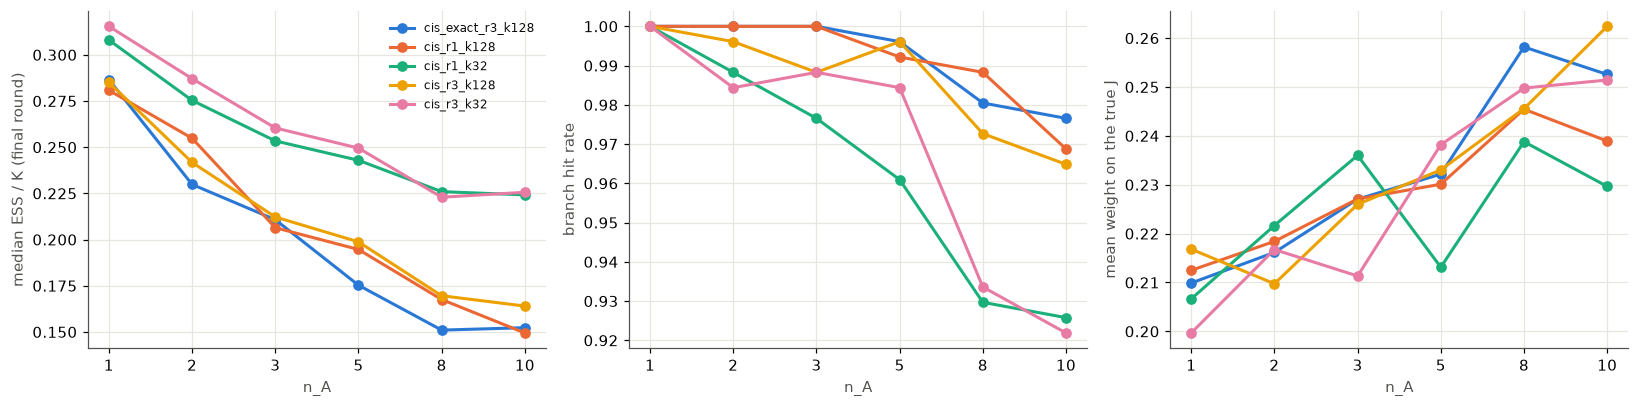

In [ ]:
dg = diag[diag.method.str.startswith("cis")].merge(tasks[["task", "ext", "h", "J"]], on="task")
dg["ess_k"] = dg.ess / dg.K
g = dg.groupby(["method", "n_a"]).agg(ess_k=("ess_k", "median"), hit=("hit", "mean"), qmass=("qmass", "mean"),
                                    pJ_true=("pJ_true", "mean"), sec=("sec_per_task", "first"))
display(g.unstack("n_a").round(3))
print("C1: branch hit rate, U (R = 1, K = 128), by extrema stratum (pass: ≥ 0.95 at n_A ≥ 2 on every stratum)")
c1 = dg[dg.method == "cis_r1_k128"].pivot_table(index="ext", columns="n_a", values="hit", aggfunc="mean")
display(c1.round(3))
c1_pass = bool((c1[[n for n in c1.columns if n >= 2]] >= 0.95).all().all())
c3 = (m[CIS] - m.isref)[[n for n in NS if n >= 2]]
c3_pass = bool((c3 <= 0.03).all())
e = dg.groupby(["method", "n_a"]).ess.median().unstack("n_a")
c4 = (e.loc[CIS] / e.loc["cis_r1_k128"])
eh = dg[dg.h == "h affine"].groupby(["method", "n_a"]).ess.median().unstack("n_a")
c4h = eh.loc[CIS] / eh.loc["cis_r1_k128"]
c4_pass = bool((c4[[n for n in NS if n >= 5]] >= 1.5).all() and (c4h[[n for n in NS if n >= 3]] >= 1.5).all())
gap = m[CIS] - m.isref
c5_pass = bool(gap.loc[1] > gap[[n for n in NS if n >= 2]].max()) if 1 in gap.index else None
c6 = dg[(dg.method == CIS) & (dg.h == "h affine")].groupby("n_a").hit.mean()
c6_pass = bool((c6[[n for n in NS if n >= 3]] >= 0.9).all())
print(pd.DataFrame([
    ("C1 coverage: hit ≥ 0.95, R=1 K=128, n_A ≥ 2, every stratum (AIR-flow clause not evaluated, D4)", c1_pass),
    ("C3 accuracy: CIS − IS-ref ≤ 0.03 at n_A ≥ 2: " + " / ".join(f"{v:.3f}" for v in c3), c3_pass),
    ("C4 rounds: ESS(R=3)/ESS(R=1) ≥ 1.5 at n_A ≥ 5: " + " / ".join(f"{c4[n]:.2f}" for n in NS if n >= 5)
     + "; h affine at n_A ≥ 3: " + " / ".join(f"{c4h[n]:.2f}" for n in NS if n >= 3), c4_pass),
    ("C5 n_A = 1 hardest: gap at 1 vs max at ≥ 2: " + (f"{gap.loc[1]:.3f} vs {gap[[n for n in NS if n >= 2]].max():.3f}" if 1 in gap.index else "n/a"), c5_pass),
    ("C6 h: hit ≥ 0.9 under h affine at n_A ≥ 3: " + " / ".join(f"{c6[n]:.2f}" for n in NS if n >= 3), c6_pass),
], columns=["hypothesis", "pass"]).to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for i, k in enumerate(sorted(dg.method.unique())):
    z = g.loc[k]
    axs[0].plot(range(len(z)), z.ess_k, marker="o", color=C[i % len(C)], label=k)
    axs[1].plot(range(len(z)), z.hit, marker="o", color=C[i % len(C)], label=k)
    axs[2].plot(range(len(z)), z.pJ_true, marker="o", color=C[i % len(C)], label=k)
for ax, yl in zip(axs, ("median ESS / K (final round)", "branch hit rate", "mean weight on the true J"), strict=True):
    ax.set_xticks(range(len(NS)), NS)
    ax.set(xlabel="n_A", ylabel=yl)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Calibration of p(J)

For the oracle and CIS: the mean posterior weight on each J, against the frequency of the true J among tasks
whose posterior puts that much weight on it (binned reliability). On the prior, a calibrated p(J | A) is reliable.

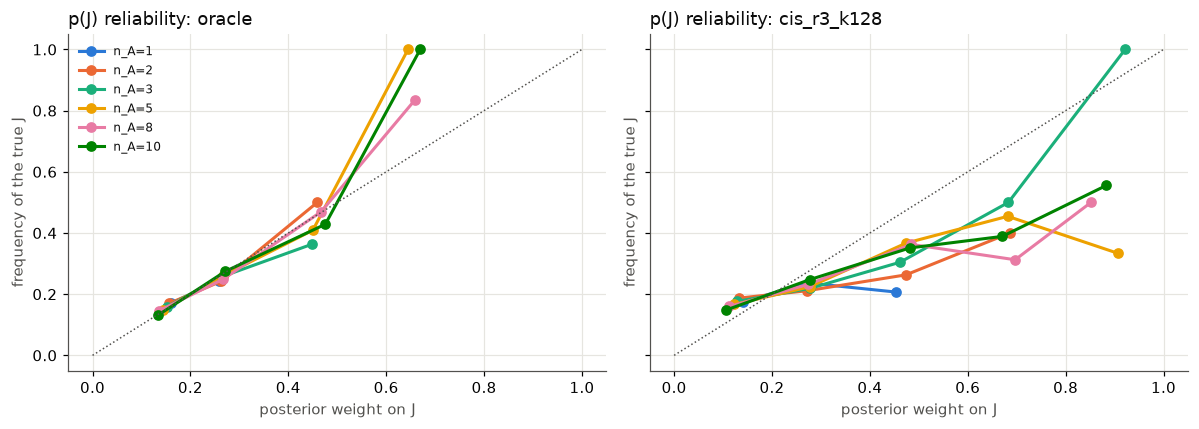

In [ ]:
oj = diag[diag.method == "oracle"].merge(tasks[["task", "J"]], on="task")
oj["is_true"] = oj.J_val == oj.J
rel = []
for src, z in (("oracle", oj[["n_a", "pJ", "is_true"]]),):
    z = z.assign(bin=pd.cut(z.pJ, np.linspace(0, 1, 6), include_lowest=True))
    rel.append(z.groupby(["n_a", "bin"], observed=True).agg(mean_p=("pJ", "mean"), freq=("is_true", "mean"), n=("pJ", "size")).assign(src=src))
cj = dg[dg.method == CIS]
long = pd.concat([cj[["n_a", f"pJ_{v}"]].rename(columns={f"pJ_{v}": "pJ"}).assign(is_true=(cj.J == v).values) for v in (0, 2, 4, 8, 16)])
long = long.assign(bin=pd.cut(long.pJ, np.linspace(0, 1, 6), include_lowest=True))
rel.append(long.groupby(["n_a", "bin"], observed=True).agg(mean_p=("pJ", "mean"), freq=("is_true", "mean"), n=("pJ", "size")).assign(src=CIS))
R = pd.concat(rel).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, src in zip(axs, ("oracle", CIS), strict=True):
    for i, n in enumerate(NS):
        z = R[(R.src == src) & (R.n_a == n)]
        ax.plot(z.mean_p, z.freq, marker="o", color=C[i % len(C)], label=f"n_A={n}")
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":")
    ax.set(xlabel="posterior weight on J", ylabel="frequency of the true J")
    ax.set_title(f"p(J) reliability: {src}", loc="left")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Predictive calibration

PIT = the predictive CDF at the held-out y. Coverage of the central 50 % / 90 % intervals = the share of PIT in
[0.25, 0.75] / [0.05, 0.95].

c50                                       c90                \
n_a             1      2      3      5      8      10     1      2      3    
method                                                                       
aonly        0.508  0.493  0.503  0.512  0.510  0.508  0.899  0.895  0.890   
cis_r3_k128  0.485  0.492  0.502  0.502  0.510  0.507  0.887  0.887  0.888   
mtpfn        0.493  0.503  0.510  0.513  0.517  0.523  0.899  0.897  0.896   
oracle       0.476  0.499  0.504  0.495  0.496  0.498  0.893  0.890  0.887   

                                  
n_a             5      8      10  
method                            
aonly        0.901  0.895  0.899  
cis_r3_k128  0.902  0.906  0.904  
mtpfn        0.901  0.903  0.907  
oracle       0.895  0.896  0.897

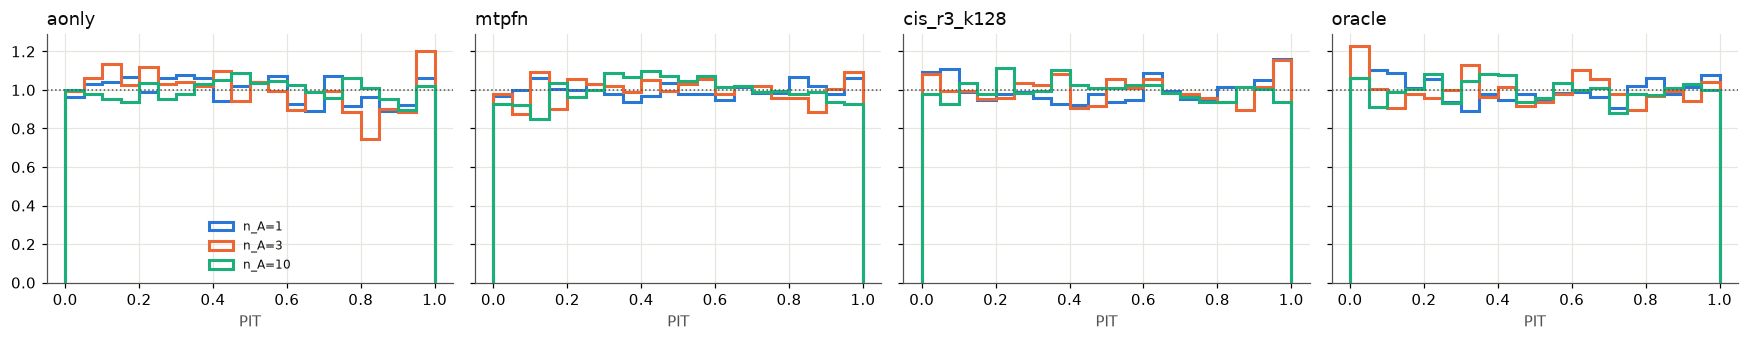

In [ ]:
MS = [k for k in ("aonly", "mtpfn", CIS, "oracle") if k in q.method.unique()]
cov = q[q.method.isin(MS)].assign(c50=lambda z: z.cdf.between(0.25, 0.75), c90=lambda z: z.cdf.between(0.05, 0.95))
display(cov.groupby(["method", "n_a"])[["c50", "c90"]].mean().unstack("n_a").round(3))
fig, axs = plt.subplots(1, len(MS), figsize=(4 * len(MS), 3.2), sharey=True)
for ax, k in zip(axs, MS, strict=True):
    for i, n in enumerate((1, 3, 10)):
        z = q[(q.method == k) & (q.n_a == n)].cdf
        ax.hist(z, bins=20, range=(0, 1), density=True, histtype="step", color=C[i], lw=2, label=f"n_A={n}")
    ax.axhline(1, color=MUTED, lw=1, ls=":")
    ax.set(xlabel="PIT")
    ax.set_title(k, loc="left")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Leak audit (a validity check of the prior)

The oracle's gain over A-only by the distance of x* to the box boundary, h = id stratum. Flagged if, within 0.05 of
the boundary, the gain exceeds 1.3 × the interior gain (notebook 16's leak gave 1.04 vs 0.61 nats, 1.7 ×).

,oracle gain edge (< 0.05),oracle gain interior,mtpfn gain edge (< 0.05),mtpfn gain interior,cis_r3_k128 gain edge (< 0.05),cis_r3_k128 gain interior,oracle edge / interior,flag (> 1.3)
n_A,,,,,,,,
1,1.178,0.890,1.007,0.730,1.101,0.788,1.324,True
2,0.901,0.614,0.728,0.453,0.784,0.502,1.468,True
3,0.734,0.494,0.577,0.319,0.611,0.369,1.485,True
5,0.572,0.326,0.425,0.173,0.492,0.240,1.755,True
8,0.523,0.235,0.365,0.104,0.446,0.151,2.229,True
10,0.481,0.213,0.327,0.084,0.377,0.125,2.255,True


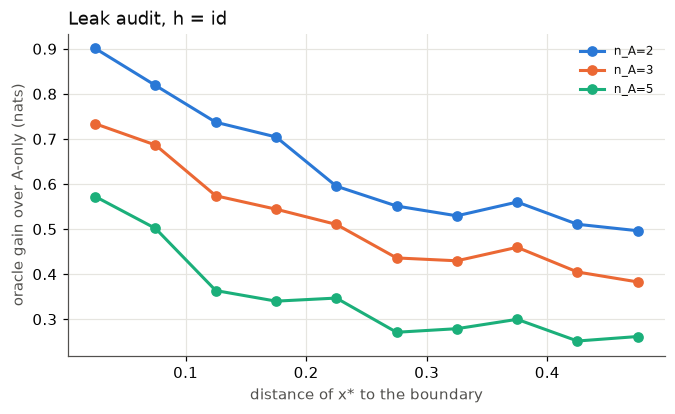

In [ ]:
qq = q[q.method.isin(["aonly", "oracle", "mtpfn", CIS])].pivot_table(index=["n_a", "task", "q"], columns="method", values="lp").reset_index()
qq = qq.merge(tasks[["task", "h_id"]], on="task").merge(q[q.method == "oracle"][["n_a", "task", "q", "x"]], on=["n_a", "task", "q"])
qq["dist"] = np.minimum(qq.x, 1 - qq.x)
qq["zone"] = np.where(qq.dist < 0.05, "edge (< 0.05)", "interior")
rows = []
for n in NS:
    z = qq[(qq.n_a == n) & qq.h_id]
    gains = {k: z.groupby("zone").apply(lambda v, k=k: (v[k] - v.aonly).mean()) for k in ("oracle", "mtpfn", CIS) if k in z}
    ratio = gains["oracle"]["edge (< 0.05)"] / gains["oracle"]["interior"]
    rows.append({"n_A": n, **{f"{k} gain {zz}": v[zz] for k, v in gains.items() for zz in v.index}, "oracle edge / interior": ratio,
                 "flag (> 1.3)": ratio > 1.3})
L = pd.DataFrame(rows).set_index("n_A")
display(L.round(3))
bins = np.linspace(0, 0.5, 11)
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, n in enumerate((2, 3, 5)):
    z = qq[(qq.n_a == n) & qq.h_id]
    b = pd.cut(z.dist, bins)
    gg = (z.oracle - z.aonly).groupby(b, observed=True).mean()
    ax.plot((bins[:-1] + bins[1:]) / 2, gg.values, marker="o", color=C[i], label=f"n_A={n}")
ax.set(xlabel="distance of x* to the boundary", ylabel="oracle gain over A-only (nats)")
ax.set_title("Leak audit, h = id", loc="left")
ax.legend(fontsize=8)
plt.show()

### 7b. Leak audit, post-hoc controls (added after the results; not pre-registered)

The pre-registered audit flags. Two controls separate a leak from A-only's weakness at the edge:
1. **Prior level:** a leak in the prior would pin f_A to g at the ends. Notebook 16's leak gave 0.003 at the ends
   against 0.055 in the middle. Shown here: the mean |f_A − g| (h = id) by x, over 4000 prior tasks.
2. **Matched queries:** edge queries are always outside A's hull, where A-only extrapolates from one side. Among
   queries outside A's hull, the edge gain is compared with the interior gain at a matched distance to the nearest
   A point (quartile bins, weighted by the edge queries' bin counts).

In [ ]:
import torch

from meta_pfn.experimental.air.cis import prior as CP

tp = CP.sample_tasks(CP.CisCfg(), 4000, 1, torch.Generator().manual_seed(11))
xg = torch.linspace(0, 1, 101)[None].expand(4000, -1)
dd = (tp.f_a(xg) - tp.g(xg)).abs()[tp.hid]
print("prior |f_A − g|, h = id: x = 0: %.3f | x < 0.05: %.3f | 0.4–0.6: %.3f | x > 0.95: %.3f | x = 1: %.3f" % (
    dd[:, 0].mean(), dd[:, :5].mean(), dd[:, 40:61].mean(), dd[:, 96:].mean(), dd[:, -1].mean()))
TE = CP.eval_tasks(256, 777, "cpu")
xa = TE.xa.numpy()
assert np.allclose(TE.xq.numpy().reshape(-1), q[(q.method == "oracle") & (q.n_a == NS[0])].x.to_numpy(), atol=1e-6)
pp = qq[qq.h_id].copy()
pp["gain"], pp["edge"] = pp.oracle - pp.aonly, pp.dist < 0.05
pp["dA"] = [np.abs(xa[t, :n] - x).min() for t, n, x in zip(pp.task, pp.n_a, pp.x, strict=True)]
pp["out"] = [(x < xa[t, :n].min()) or (x > xa[t, :n].max()) for t, n, x in zip(pp.task, pp.n_a, pp.x, strict=True)]
rows = []
for n in NS:
    z = pp[(pp.n_a == n) & pp.out]
    b = pd.qcut(z.dA, 4, duplicates="drop")
    g_ = z.groupby([b, "edge"], observed=True).gain.mean().unstack()
    cnt = z.groupby([b, "edge"], observed=True).size().unstack()
    m_ = (g_[False] * cnt[True] / cnt[True].sum()).sum()
    e_ = z[z.edge].gain
    rows.append({"n_A": n, "edge gain": e_.mean(), "edge SE": e_.std() / np.sqrt(len(e_)), "n edge": len(e_),
                 "interior gain, matched": m_, "n interior": int((~z.edge).sum()), "ratio": e_.mean() / m_})
display(pd.DataFrame(rows).set_index("n_A").round(3))

prior |f_A − g|, h = id: x = 0: 0.040 | x < 0.05: 0.042 | 0.4–0.6: 0.036 | x > 0.95: 0.024 | x = 1: 0.022


,edge gain,edge SE,n edge,"interior gain, matched",n interior,ratio
n_A,,,,,,
1,1.178,0.061,329,1.075,3255,1.096
2,0.933,0.058,313,0.903,2180,1.032
3,0.768,0.058,308,0.768,1451,1.001
5,0.605,0.059,297,0.580,896,1.043
8,0.564,0.059,277,0.587,556,0.961
10,0.552,0.056,258,0.594,443,0.929


## 8. Strata, negative transfer, runtime

The NLL by true J, by extrema of g and by h (n_A = 3), and the share of tasks where a method is worse than A-only.

In [ ]:
z = nll[(nll.n_a == 3) & nll.method.isin(["aonly", "mtpfn", CIS, "isref", "oracle"])]
for s in ("J", "ext", "h"):
    display(z.pivot_table(index=s, columns="method", values="nll", aggfunc="mean").round(3))
neg = pd.DataFrame({k: (P[k] > P.aonly).groupby("n_a").mean() for k in ("mtpfn", CIS, "isref", "oracle") if k in P})
print("share of tasks worse than A-only")
display(neg.round(3))
rt = diag[diag.method.str.startswith("cis")].groupby(["method", "n_a"]).sec_per_task.first().unstack("n_a")
print("CIS wall time per task (s; GPU, batched 32 tasks)")
display(rt.round(3))

method,aonly,cis_r3_k128,isref,mtpfn,oracle
J,,,,,
0,-1.889,-2.282,-2.291,-2.223,-2.387
2,-1.876,-2.154,-2.186,-2.122,-2.308
4,-1.930,-2.146,-2.170,-2.118,-2.278
8,-1.941,-2.196,-2.190,-2.147,-2.246
16,-2.016,-2.188,-2.196,-2.155,-2.261


method,aonly,cis_r3_k128,isref,mtpfn,oracle
ext,,,,,
0,-2.068,-2.322,-2.328,-2.292,-2.425
1,-1.887,-2.182,-2.197,-2.125,-2.294
2,-1.844,-2.137,-2.157,-2.081,-2.252
≥3,-1.617,-1.817,-1.870,-1.856,-1.933


method,aonly,cis_r3_k128,isref,mtpfn,oracle
h,,,,,
h = id,-1.819,-2.210,-2.238,-2.162,-2.335
h affine,-2.001,-2.183,-2.189,-2.149,-2.280


share of tasks worse than A-only


,mtpfn,cis_r3_k128,isref,oracle
n_a,,,,
1,0.141,0.152,0.148,0.109
2,0.211,0.176,0.176,0.121
3,0.195,0.199,0.180,0.117
5,0.246,0.234,0.223,0.133
8,0.246,0.242,0.211,0.109
10,0.227,0.227,0.195,0.113


CIS wall time per task (s; GPU, batched 32 tasks)


n_a,1,2,3,5,8,10
method,,,,,,
cis_exact_r3_k128,0.893,1.232,1.519,2.090,2.656,3.293
cis_r1_k128,0.360,0.485,0.645,0.881,1.244,1.297
cis_r1_k32,0.291,0.383,0.475,0.630,0.872,0.979
cis_r3_k128,0.918,1.269,1.556,2.114,2.648,3.210
cis_r3_k32,0.844,1.135,1.397,1.859,2.558,2.885


## Reading (pilot, seed 0 for every learned part; the verdict is proposed, not decided)

**Runs.**
- Decoder: `pilot_20261104-174531` (plateau stop at 28 000 steps).
- MTPFN: `pilot_20261104-175731`; A-only PFN: `pilot_20261104-183902` (100 000 steps each).
- Evaluation: `pilot_20261104-202203` (commit edd69cd, clean). 256 tasks per n_A, all members DONE, none failed.
- The ablation decoder without the T′ feature (`pilot_20261104-201833`) finished after the evaluation started, so
  C8 is not evaluated.

**Pre-registered comparison: INCONCLUSIVE.**
- CIS-U (R = 3, K = 128) is better than MTPFN at every n_A, by 0.030 / 0.030 / 0.040 / 0.045 / 0.029 / 0.029 nats
  at n_A = 1 / 2 / 3 / 5 / 8 / 10.
- Every paired 95 % CI excludes 0, but no cell reaches the 0.05 margin.
- CIS is better on 57–66 % of tasks.

**The ladder.**
- Share of the A-only → oracle gap closed, from n_A = 1 to 10:
  - MTPFN 80 % → 39 %;
  - CIS 85 % → 54 %;
  - IS-ref 86 % → 60 %.
- Both learners lose ground as n_A grows. MTPFN's amortisation error (MTPFN − oracle) is 0.12–0.15 nats.

**Where CIS's error is.** Almost all of it is the decoder, not the proposal.
- Proposal error (CIS − IS-ref): 0.008–0.017. This passes C3 (≤ 0.03).
- Decoder error (IS-ref − oracle): 0.081–0.096.
- With the exact likelihood, the same proposal is within 0.04–0.05 of the oracle at n_A ≤ 8.
- The teacher (the decoder given the true θ and J) beats the oracle by 0.02–0.22. It conditions on latents the
  oracle has to infer, so it is not a bound.
- The next lever is therefore the decoder: it stopped by the plateau rule at 28k steps, and only one seed exists.
  More proposal work is not the lever.

**Hypotheses.**
- C1 fails, and only on the ≥ 3-extrema stratum (20 tasks): hit rate 0.95 / 0.85 / 0.75 at n_A = 5 / 8 / 10. Every
  other stratum is ≥ 0.94, and most are 1.0.
- C3 passes.
- C4 fails: the rounds do not raise the ESS (ratio 1.0–1.1).
- C5 fails: n_A = 1 is not the hardest case for the proposal.
- C6 passes: hit rate ≥ 0.96 under affine h.
- C2 and C1's AIR-flow clause are not evaluated (D4).

**p(J) is barely identified.** The weight on the true J is 0.21–0.26 for CIS. This is close to the prior, so the
complexity posterior adds little here. The oracle's p(J) is calibrated. CIS's is overconfident where it puts more than 0.5 on one J (§5, reliability), either from the decoder's evidence or from weight degeneracy at K = 128 (not separated here).

**Calibration.** The 90 % coverage is 0.887–0.907 for A-only, MTPFN, CIS and the oracle.

**Negative transfer.** Share of tasks worse than A-only:
- MTPFN 14–25 %;
- CIS 15–24 %;
- oracle 11–13 %.

**Leak audit.** The pre-registered audit flags: the ratio is 1.32–2.26. Two post-hoc controls (§7b) attribute it
to A-only's one-sided extrapolation at the edge, not to a leak:
- In the prior, |f_A − g| is 0.022–0.042 at the ends against 0.036 in the middle. Notebook 16's leak was 0.003
  against 0.055.
- Among queries outside A's hull, at a matched distance to the nearest A point, the edge/interior ratio is
  0.93–1.10.

**Runtime.** CIS-U (R = 3, K = 128) takes 0.9–3.2 s per task on the GPU; MTPFN is a single forward pass.

**Limits.**
- One training seed for every learned part.
- The oracle's MC error is 0.014–0.020 nats per task (mean |half 1 − half 2|).
- The ≥ 3-extrema stratum has 20 tasks.
